# A/B-тест нового алгоритма рекомендаций

**Портфолио-проект по продуктовой аналитике**

Команда развлекательного приложения разработала новый алгоритм рекомендаций для бесконечной ленты. Нужно спроектировать эксперимент, проверить корректность рандомизации и определить, увеличивает ли новый алгоритм долю успешных первых сессий — сессий, в которых пользователь просмотрел не менее четырёх страниц.

Проект охватывает полный цикл эксперимента: исторический baseline, расчёт мощности и выборки, оценку eligible-трафика, мониторинг SRM и баланса ковариат, анализ эффекта с доверительным интервалом и проверку устойчивости вывода к проблемам качества данных.

## 1. Аналитический дизайн

**Единица рандомизации и анализа:** пользователь.

**Контроль A:** прежний алгоритм рекомендаций.  
**Тест B:** новый алгоритм рекомендаций.

**Основная метрика:** доля пользователей, просмотревших не менее четырёх страниц в первой сессии.

**Статистические гипотезы:**

- H₀: доли успешных первых сессий в A и B равны;
- H₁: доли различаются.

Используется двусторонний тест: он позволяет обнаружить как улучшение, так и ухудшение. Для запуска алгоритма одного значимого различия недостаточно — эффект должен быть положительным, а доверительный интервал должен исключать ноль. Плановый MDE равен **3 процентным пунктам**, α = 0,05, мощность = 80%.

Доступные дополнительные показатели — среднее число страниц и регистрация в первой сессии. Полноценных барьерных метрик (ошибки, задержка, жалобы, удержание) в данных нет.

In [1]:
from pathlib import Path
from math import ceil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import brentq
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"A": "#64748B", "B": "#2563EB"}
ALPHA = 0.05
POWER = 0.80
PLANNED_MDE = 0.03
RANDOM_STATE = 42

## 2. Данные

| Таблица | Назначение |
|---|---|
| `sessions_project_history.csv` | Исторические сессии для baseline и оценки трафика |
| `sessions_project_test_part.csv` | Первый день эксперимента для раннего мониторинга |
| `sessions_project_test.csv` | Полный период наблюдения эксперимента |

Ключевые поля: пользователь и сессия, даты установки и сессии, номер сессии, количество страниц, регион, устройство и экспериментальная группа.

Ноутбук сначала ищет данные в папке `data/`, а при её отсутствии загружает учебные датасеты по ссылкам Яндекс Практикума.

In [2]:
DATA_DIR = Path("data")
URLS = {
    "sessions_project_history.csv": "https://code.s3.yandex.net/datasets/sessions_project_history.csv",
    "sessions_project_test_part.csv": "https://code.s3.yandex.net/datasets/sessions_project_test_part.csv",
    "sessions_project_test.csv": "https://code.s3.yandex.net/datasets/sessions_project_test.csv",
}
DATE_COLUMNS = ["session_date", "session_start_ts", "install_date"]


def read_dataset(filename: str) -> pd.DataFrame:
    local_path = DATA_DIR / filename
    source = local_path if local_path.exists() else URLS[filename]
    return pd.read_csv(source, parse_dates=DATE_COLUMNS)


history = read_dataset("sessions_project_history.csv")
test_part = read_dataset("sessions_project_test_part.csv")
test = read_dataset("sessions_project_test.csv")

datasets = {"history": history, "test_part": test_part, "test": test}
overview = []
for name, frame in datasets.items():
    overview.append(
        {
            "таблица": name,
            "строки": len(frame),
            "пользователи": frame["user_id"].nunique(),
            "сессии": frame["session_id"].nunique(),
            "начало": frame["session_date"].min().date(),
            "окончание": frame["session_date"].max().date(),
            "дни наблюдения": frame["session_date"].nunique(),
            "дубликаты": frame.duplicated().sum(),
            "пропуски": frame.isna().sum().sum(),
        }
    )

overview = pd.DataFrame(overview)
display(overview)

,таблица,строки,пользователи,сессии,начало,окончание,дни наблюдения,дубликаты,пропуски
0,history,435924,134039,435924,2025-08-11,2025-09-23,44,0,0
1,test_part,3130,2943,3130,2025-10-14,2025-10-14,1,0,0
2,test,100005,30579,100005,2025-10-14,2025-11-02,20,0,0


## 3. Контроль качества данных

Перед расчётами проверяются уникальность сессий, пропуски, дубликаты, постоянство экспериментальной группы и логическая согласованность дат. Последняя проверка особенно важна: первая сессия не может происходить раньше даты установки приложения.

In [3]:
for name, frame in datasets.items():
    assert frame["session_id"].is_unique, f"{name}: session_id не уникален"
    assert frame.isna().sum().sum() == 0, f"{name}: обнаружены пропуски"
    assert frame.duplicated().sum() == 0, f"{name}: обнаружены полные дубликаты"

assert test.groupby("user_id")["test_group"].nunique().max() == 1
assert test_part.groupby("user_id")["test_group"].nunique().max() == 1

history_first = history.loc[history["session_number"].eq(1)].copy()
test_first = test.loc[test["session_number"].eq(1)].copy()

history_first["good_session"] = history_first["page_counter"].ge(4)
test_first["good_session"] = test_first["page_counter"].ge(4)
test_first["delay_days"] = (
    test_first["session_date"] - test_first["install_date"]
).dt.days

assigned_users = test.groupby("test_group")["user_id"].nunique().reindex(["A", "B"])
outcome_users = test_first.groupby("test_group")["user_id"].nunique().reindex(["A", "B"])

quality_findings = pd.DataFrame(
    {
        "проверка": [
            "Пользователи одновременно в A и B",
            "Пользователи без записи первой сессии",
            "Первые сессии раньше даты установки",
            "Все сессии раньше даты установки",
        ],
        "результат": [
            test.groupby("user_id")["test_group"].nunique().gt(1).sum(),
            int((assigned_users - outcome_users).sum()),
            int(test_first["delay_days"].lt(0).sum()),
            int((test["session_date"] < test["install_date"]).sum()),
        ],
    }
)
display(quality_findings)

invalid_first_by_group = (
    test_first.loc[test_first["delay_days"].lt(0)]
    .groupby("test_group")["good_session"]
    .agg(записи="size", успешные="sum", доля="mean")
    .reindex(["A", "B"])
)
display(invalid_first_by_group)

,проверка,результат
0,Пользователи одновременно в A и B,0
1,Пользователи без записи первой сессии,1
2,Первые сессии раньше даты установки,78
3,Все сессии раньше даты установки,350


,записи,успешные,доля
test_group,,,
A,21,6,0.2857
B,57,49,0.8596


В эксперименте нет пересечений групп, но есть два дефекта:

- у одного пользователя группы A отсутствует запись `session_number = 1`;
- 78 первых сессий датированы раньше установки приложения, причём проблема распределена между группами неравномерно.

Удалять такие строки из единственного основного анализа рискованно: исключение после рандомизации может внести смещение. Поэтому ниже показаны два результата:

1. основной анализ по заранее определённому правилу `session_number = 1`;
2. анализ чувствительности без хронологически невозможных записей.

Если оба варианта приводят к одному решению, бизнес-вывод можно считать устойчивым к этой проблеме данных.

## 4. Исторический baseline и eligible-трафик

Основная метрика формируется только в первой сессии. Следовательно, для расчёта длительности эксперимента нужен поток **новых пользователей с первой сессией**, а не весь DAU. Использование общего числа активных пользователей завышает доступный трафик.

In [4]:
daily_history = (
    history_first.groupby("session_date", as_index=False)
    .agg(
        eligible_users=("user_id", "nunique"),
        success_rate=("good_session", "mean"),
        registrations=("registration_flag", "sum"),
    )
)

baseline_rate = history_first["good_session"].mean()
avg_daily_eligible = daily_history["eligible_users"].mean()

historical_summary = pd.DataFrame(
    {
        "показатель": [
            "Первые сессии",
            "Baseline успешных первых сессий",
            "Средний eligible-трафик в день",
            "Медианный eligible-трафик в день",
            "Период привлечения новых пользователей",
            "Полный период наблюдения сессий",
        ],
        "значение": [
            f"{len(history_first):,}",
            f"{baseline_rate:.2%}",
            f"{avg_daily_eligible:,.0f}",
            f"{daily_history['eligible_users'].median():,.0f}",
            f"{history_first['install_date'].min():%d.%m.%Y} — {history_first['install_date'].max():%d.%m.%Y}",
            f"{history['session_date'].min():%d.%m.%Y} — {history['session_date'].max():%d.%m.%Y}",
        ],
    }
)
display(historical_summary)

,показатель,значение
0,Первые сессии,"134,039"
1,Baseline успешных первых сессий,31.06%
2,Средний eligible-трафик в день,"4,324"
3,Медианный eligible-трафик в день,"3,988"
4,Период привлечения новых пользователей,11.08.2025 — 10.09.2025
5,Полный период наблюдения сессий,11.08.2025 — 23.09.2025


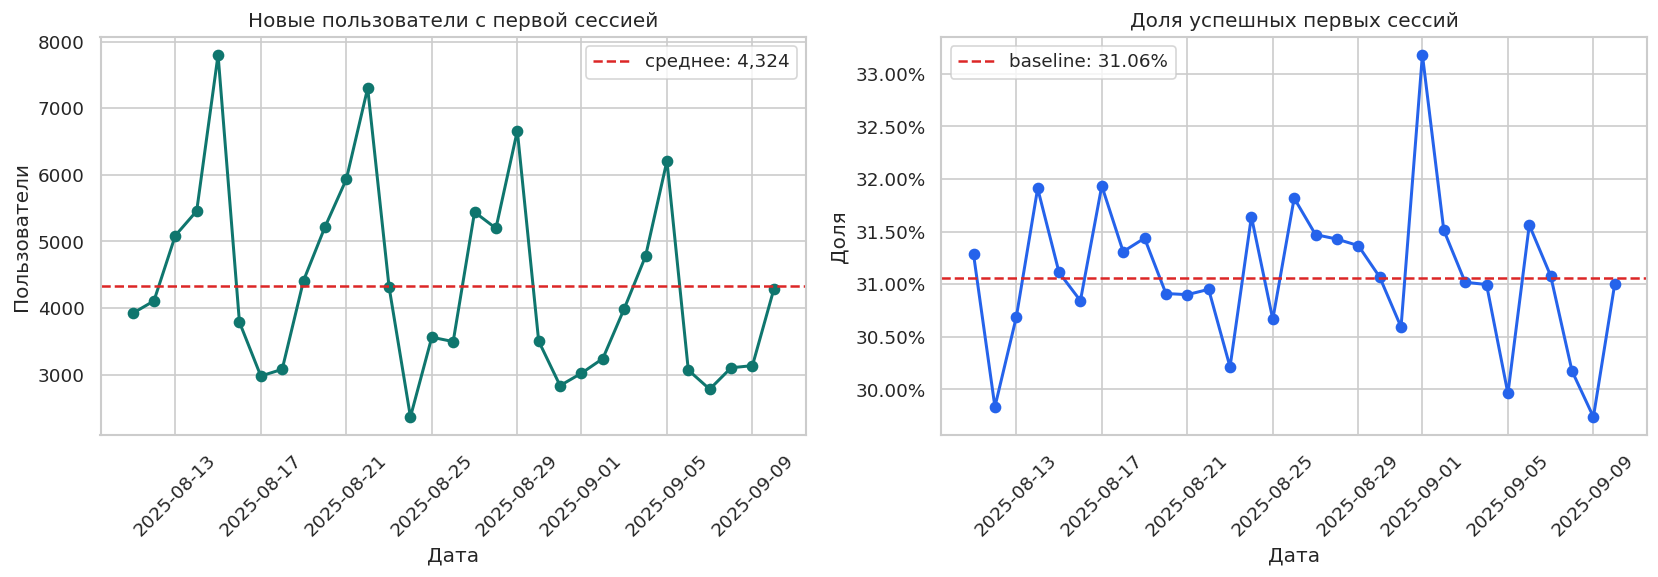

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    daily_history["session_date"], daily_history["eligible_users"],
    marker="o", linewidth=1.8, color="#0F766E",
)
axes[0].axhline(
    avg_daily_eligible, color="#DC2626", linestyle="--",
    label=f"среднее: {avg_daily_eligible:,.0f}",
)
axes[0].set(
    title="Новые пользователи с первой сессией",
    xlabel="Дата", ylabel="Пользователи",
)
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].plot(
    daily_history["session_date"], daily_history["success_rate"],
    marker="o", linewidth=1.8, color="#2563EB",
)
axes[1].axhline(
    baseline_rate, color="#DC2626", linestyle="--",
    label=f"baseline: {baseline_rate:.2%}",
)
axes[1].set(
    title="Доля успешных первых сессий",
    xlabel="Дата", ylabel="Доля",
)
axes[1].tick_params(axis="x", rotation=45)
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].legend()

plt.tight_layout()
plt.show()

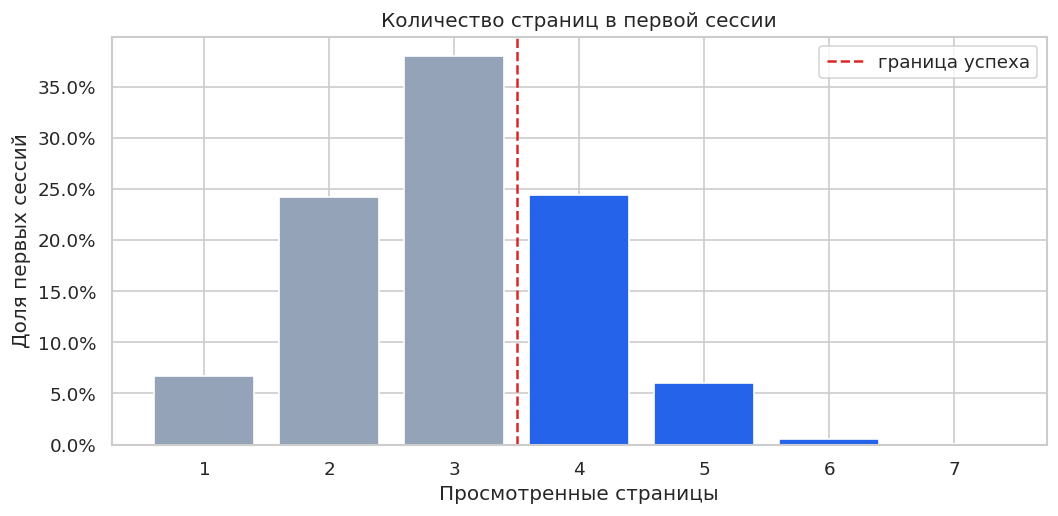

In [6]:
pages_distribution = (
    history_first["page_counter"]
    .value_counts(normalize=True)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#94A3B8" if pages < 4 else "#2563EB" for pages in pages_distribution.index]
ax.bar(pages_distribution.index, pages_distribution.values, color=colors)
ax.axvline(3.5, color="#DC2626", linestyle="--", label="граница успеха")
ax.set(
    title="Количество страниц в первой сессии",
    xlabel="Просмотренные страницы",
    ylabel="Доля первых сессий",
)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend()
plt.tight_layout()
plt.show()

## 5. Размер выборки и длительность набора

Размер выборки рассчитывается от фактического исторического baseline, а не от округлённого значения 30%. Для двух независимых долей используется эффект Коэна h и двусторонний уровень значимости 5%.

In [7]:
def proportion_effect_size(p_control: float, p_test: float) -> float:
    return 2 * np.arcsin(np.sqrt(p_test)) - 2 * np.arcsin(np.sqrt(p_control))


def required_sample_per_group(
    p_control: float,
    mde: float,
    alpha: float = 0.05,
    power: float = 0.80,
) -> int:
    effect = abs(proportion_effect_size(p_control, p_control + mde))
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_power = stats.norm.ppf(power)
    return ceil(2 * ((z_alpha + z_power) / effect) ** 2)


required_n = required_sample_per_group(
    p_control=baseline_rate,
    mde=PLANNED_MDE,
    alpha=ALPHA,
    power=POWER,
)
minimum_recruitment_days = ceil(2 * required_n / avg_daily_eligible)

design_table = pd.DataFrame(
    {
        "параметр": [
            "Исторический baseline",
            "MDE",
            "Уровень значимости",
            "Мощность",
            "Выборка на группу",
            "Минимальный набор при среднем трафике",
            "Операционная рекомендация",
        ],
        "значение": [
            f"{baseline_rate:.2%}",
            f"{PLANNED_MDE:.0%} = 3 п.п.",
            f"{ALPHA:.0%}",
            f"{POWER:.0%}",
            f"{required_n:,} пользователей",
            f"{minimum_recruitment_days} дня",
            "не менее 7 дней набора",
        ],
    }
)
display(design_table)

,параметр,значение
0,Исторический baseline,31.06%
1,MDE,3% = 3 п.п.
2,Уровень значимости,5%
3,Мощность,80%
4,Выборка на группу,"3,828 пользователей"
5,Минимальный набор при среднем трафике,2 дня
6,Операционная рекомендация,не менее 7 дней набора


Математически нужный объём можно собрать примерно за два дня. Однако трафик заметно меняется по дням недели, поэтому запуск всего на два дня создаёт риск календарного смещения. Практический план — **семь полных дней набора** плюс необходимое окно наблюдения для заранее выбранных барьерных метрик.

В фактическом эксперименте новые пользователи набирались с 14 по 20 октября — ровно семь дней. Сессии отслеживались до 2 ноября, поэтому полный файл охватывает 20 календарных дней. Эти два интервала нельзя смешивать: 20 дней — окно наблюдения, а не длительность набора основной метрики.

## 6. Мониторинг рандомизации

Проверяются четыре риска:

1. **SRM** — несоответствие фактического распределения ожидаемому 50/50;
2. пересечение пользователей между группами;
3. дисбаланс по устройствам и регионам;
4. дисбаланс по дням включения в эксперимент.

Для SRM используется точный биномиальный тест, для категориальных признаков — χ²-тест независимости.

In [8]:
def unique_group_counts(frame: pd.DataFrame) -> pd.Series:
    return frame.groupby("test_group")["user_id"].nunique().reindex(["A", "B"])


def srm_p_value(counts: pd.Series) -> float:
    return stats.binomtest(
        k=int(counts.loc["B"]),
        n=int(counts.sum()),
        p=0.5,
        alternative="two-sided",
    ).pvalue


part_counts = unique_group_counts(test_part)
full_counts = unique_group_counts(test)

monitoring_summary = pd.DataFrame(
    {
        "период": ["Первый день", "Полный набор"],
        "A": [part_counts["A"], full_counts["A"]],
        "B": [part_counts["B"], full_counts["B"]],
        "разница, % от A": [
            abs(part_counts["A"] - part_counts["B"]) / part_counts["A"] * 100,
            abs(full_counts["A"] - full_counts["B"]) / full_counts["A"] * 100,
        ],
        "SRM p-value": [srm_p_value(part_counts), srm_p_value(full_counts)],
        "пересечения": [
            test_part.groupby("user_id")["test_group"].nunique().gt(1).sum(),
            test.groupby("user_id")["test_group"].nunique().gt(1).sum(),
        ],
    }
)
display(monitoring_summary.round(4))

,период,A,B,"разница, % от A",SRM p-value,пересечения
0,Первый день,1477,1466,0.7448,0.8538,0
1,Полный набор,15163,15416,1.6685,0.1496,0


,признак,χ² p-value,"макс. разница, п.п."
0,Устройство,0.8066,0.4710
1,Регион,0.5544,0.5766
2,Дата включения,0.3875,0.5518


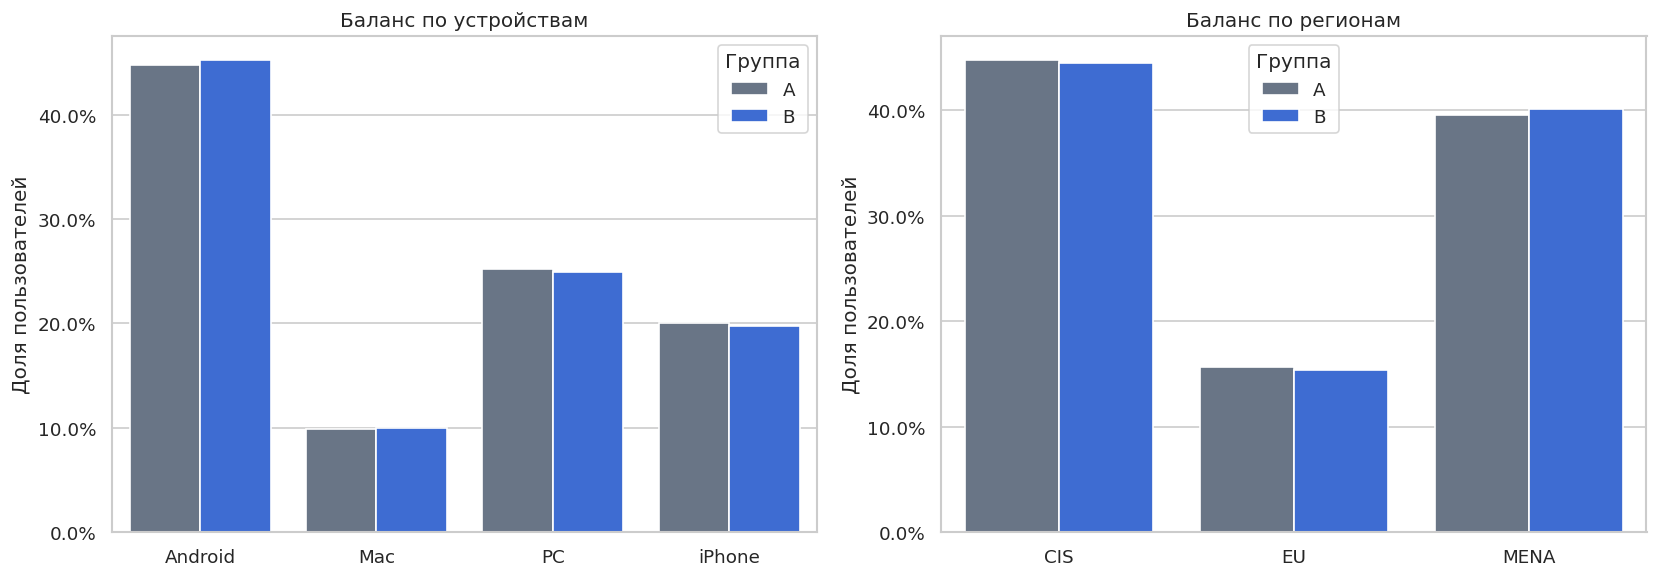

In [9]:
test_users = (
    test.sort_values("session_start_ts")
    .drop_duplicates("user_id")
    .copy()
)


def balance_test(frame: pd.DataFrame, column: str):
    contingency = pd.crosstab(frame["test_group"], frame[column]).reindex(["A", "B"])
    chi2, p_value, _, _ = stats.chi2_contingency(contingency)
    shares = contingency.div(contingency.sum(axis=1), axis=0)
    max_difference = (shares.loc["B"] - shares.loc["A"]).abs().max()
    return contingency, shares, p_value, max_difference


balance_rows = []
balance_shares = {}
for column, label in [
    ("device", "Устройство"),
    ("region", "Регион"),
    ("install_date", "Дата включения"),
]:
    _, shares, p_value, max_difference = balance_test(test_users, column)
    balance_shares[column] = shares
    balance_rows.append(
        {
            "признак": label,
            "χ² p-value": p_value,
            "макс. разница, п.п.": max_difference * 100,
        }
    )

balance_summary = pd.DataFrame(balance_rows)
display(balance_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, title in zip(
    axes,
    ["device", "region"],
    ["Баланс по устройствам", "Баланс по регионам"],
):
    plot_data = (
        balance_shares[column]
        .T.reset_index(names="category")
        .melt(id_vars="category", var_name="test_group", value_name="share")
    )
    sns.barplot(
        data=plot_data, x="category", y="share", hue="test_group",
        hue_order=["A", "B"], palette=COLORS, ax=ax,
    )
    ax.set(title=title, xlabel="", ylabel="Доля пользователей")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.legend(title="Группа")

plt.tight_layout()
plt.show()

SRM не обнаружен ни в первый день, ни после завершения набора: p-value выше 0,05. Пересечений пользователей нет. Распределения устройств, регионов и дат включения также не дают оснований отвергать гипотезу о независимости признака и группы. Это не доказывает идеальную идентичность выборок, но существенных признаков сбоя рандомизации нет.

## 7. Результат основной метрики

Эффект определяется как \(p_B - p_A\). Помимо p-value рассчитывается 95%-й доверительный интервал абсолютной разницы. Он отвечает на более полезный вопрос: какие положительные и отрицательные эффекты совместимы с данными?

In [10]:
def two_proportion_result(frame: pd.DataFrame) -> dict:
    summary = (
        frame.groupby("test_group")["good_session"]
        .agg(successes="sum", users="size", rate="mean")
        .reindex(["A", "B"])
    )

    success_a, n_a, rate_a = summary.loc["A", ["successes", "users", "rate"]]
    success_b, n_b, rate_b = summary.loc["B", ["successes", "users", "rate"]]

    difference = rate_b - rate_a
    pooled_rate = (success_a + success_b) / (n_a + n_b)
    pooled_se = np.sqrt(pooled_rate * (1 - pooled_rate) * (1 / n_a + 1 / n_b))
    z_statistic = difference / pooled_se
    p_value_two_sided = 2 * stats.norm.sf(abs(z_statistic))
    p_value_superiority = stats.norm.sf(z_statistic)

    unpooled_se = np.sqrt(
        rate_a * (1 - rate_a) / n_a
        + rate_b * (1 - rate_b) / n_b
    )
    critical = stats.norm.ppf(0.975)
    ci_low = difference - critical * unpooled_se
    ci_high = difference + critical * unpooled_se

    risk_ratio = rate_b / rate_a
    log_rr_se = np.sqrt(
        (1 - rate_b) / success_b
        + (1 - rate_a) / success_a
    )
    rr_low = np.exp(np.log(risk_ratio) - critical * log_rr_se)
    rr_high = np.exp(np.log(risk_ratio) + critical * log_rr_se)

    return {
        "summary": summary,
        "rate_a": rate_a,
        "rate_b": rate_b,
        "difference": difference,
        "relative_change": difference / rate_a,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "z": z_statistic,
        "p_two_sided": p_value_two_sided,
        "p_superiority": p_value_superiority,
        "risk_ratio": risk_ratio,
        "rr_low": rr_low,
        "rr_high": rr_high,
    }


primary = two_proportion_result(test_first)
valid_timestamps = two_proportion_result(test_first.loc[test_first["delay_days"].ge(0)])

display(primary["summary"])

primary_result = pd.DataFrame(
    {
        "метрика": [
            "Доля A",
            "Доля B",
            "Эффект B − A",
            "Относительное изменение",
            "95% ДИ эффекта",
            "Двусторонний p-value",
            "Односторонний p-value превосходства",
            "Risk ratio (95% ДИ)",
        ],
        "значение": [
            f"{primary['rate_a']:.2%}",
            f"{primary['rate_b']:.2%}",
            f"{primary['difference'] * 100:.2f} п.п.",
            f"{primary['relative_change']:.2%}",
            f"[{primary['ci_low'] * 100:.2f}; {primary['ci_high'] * 100:.2f}] п.п.",
            f"{primary['p_two_sided']:.6f}",
            f"{primary['p_superiority']:.6f}",
            f"{primary['risk_ratio']:.4f} [{primary['rr_low']:.4f}; {primary['rr_high']:.4f}]",
        ],
    }
)
display(primary_result)

,successes,users,rate
test_group,,,
A,4787,15162,0.3157
B,4851,15416,0.3147


,метрика,значение
0,Доля A,31.57%
1,Доля B,31.47%
2,Эффект B − A,-0.11 п.п.
3,Относительное изменение,-0.33%
4,95% ДИ эффекта,[-1.15; 0.94] п.п.
5,Двусторонний p-value,0.843295
6,Односторонний p-value превосходства,0.578352
7,Risk ratio (95% ДИ),0.9967 [0.9643; 1.0302]


In [11]:
def achieved_mde(
    p_control: float,
    n_per_group: int,
    alpha: float = 0.05,
    power: float = 0.80,
) -> float:
    target_effect = np.sqrt(2 / n_per_group) * (
        stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    )
    return brentq(
        lambda uplift: proportion_effect_size(p_control, p_control + uplift) - target_effect,
        1e-9,
        1 - p_control - 1e-9,
    )


actual_n = int(primary["summary"]["users"].min())
actual_mde = achieved_mde(baseline_rate, actual_n, ALPHA, POWER)

sensitivity_results = pd.DataFrame(
    [
        {
            "вариант": "Все первые сессии",
            "A": primary["rate_a"],
            "B": primary["rate_b"],
            "delta": primary["difference"],
            "ci_low": primary["ci_low"],
            "ci_high": primary["ci_high"],
            "p_value": primary["p_two_sided"],
        },
        {
            "вариант": "Без невозможных дат",
            "A": valid_timestamps["rate_a"],
            "B": valid_timestamps["rate_b"],
            "delta": valid_timestamps["difference"],
            "ci_low": valid_timestamps["ci_low"],
            "ci_high": valid_timestamps["ci_high"],
            "p_value": valid_timestamps["p_two_sided"],
        },
    ]
)

formatted_sensitivity = pd.DataFrame(
    {
        "вариант": sensitivity_results["вариант"],
        "A": sensitivity_results["A"].map(lambda value: f"{value:.2%}"),
        "B": sensitivity_results["B"].map(lambda value: f"{value:.2%}"),
        "B − A": sensitivity_results["delta"].map(lambda value: f"{value * 100:.2f} п.п."),
        "95% ДИ": sensitivity_results.apply(
            lambda row: f"[{row['ci_low'] * 100:.2f}; {row['ci_high'] * 100:.2f}] п.п.", axis=1
        ),
        "p-value": sensitivity_results["p_value"].map(lambda value: f"{value:.6f}"),
    }
)
display(formatted_sensitivity)
print(f"При фактическом объёме данных достижимый MDE ≈ {actual_mde * 100:.2f} п.п.")

При фактическом объёме данных достижимый MDE ≈ 1.50 п.п.


,вариант,A,B,B − A,95% ДИ,p-value
0,Все первые сессии,31.57%,31.47%,-0.11 п.п.,[-1.15; 0.94] п.п.,0.843295
1,Без невозможных дат,31.58%,31.27%,-0.31 п.п.,[-1.35; 0.73] п.п.,0.557957


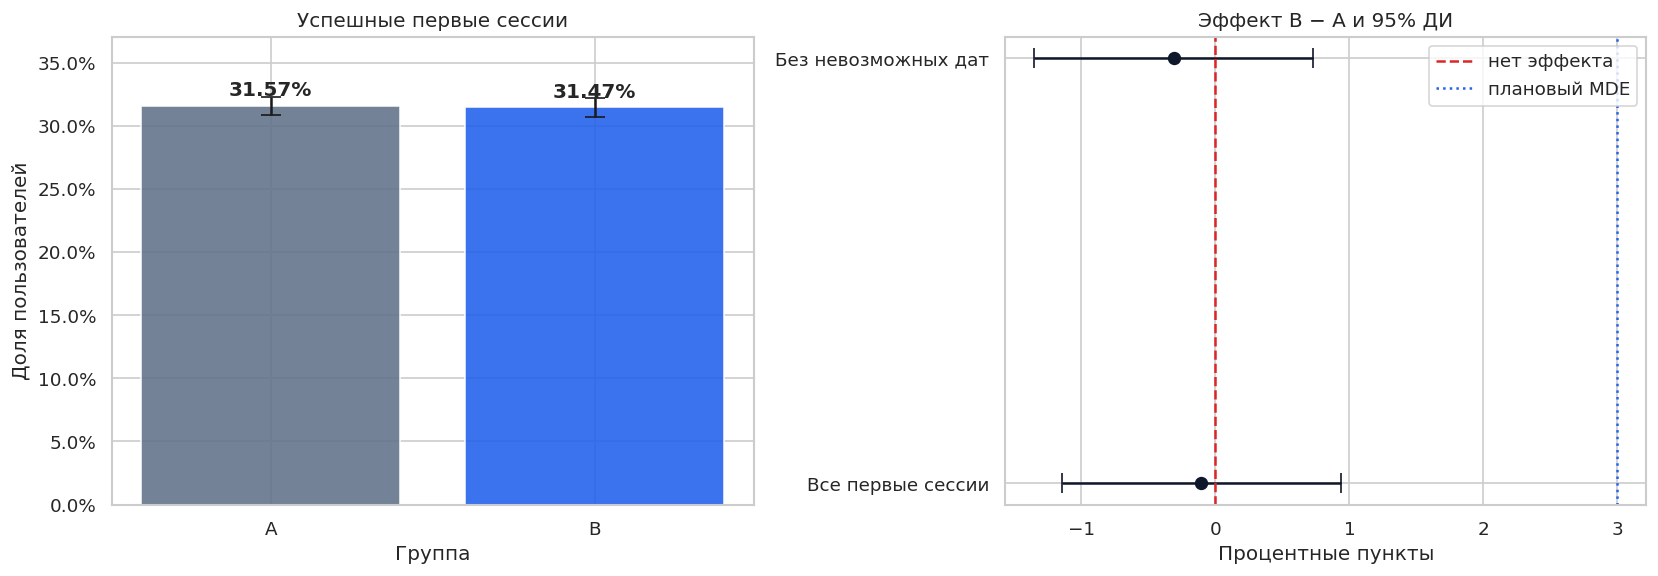

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rates = primary["summary"]["rate"]
rate_errors = 1.96 * np.sqrt(rates * (1 - rates) / primary["summary"]["users"])
axes[0].bar(
    ["A", "B"], rates.values,
    yerr=rate_errors.values, capsize=6,
    color=[COLORS["A"], COLORS["B"]], alpha=0.9,
)
axes[0].set(
    title="Успешные первые сессии",
    xlabel="Группа", ylabel="Доля пользователей",
)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for index, value in enumerate(rates.values):
    axes[0].text(index, value + 0.008, f"{value:.2%}", ha="center", fontweight="bold")
axes[0].set_ylim(0, max(rates.values) + 0.055)

y_positions = np.arange(len(sensitivity_results))
effects_pp = sensitivity_results["delta"] * 100
left_errors = effects_pp - sensitivity_results["ci_low"] * 100
right_errors = sensitivity_results["ci_high"] * 100 - effects_pp
axes[1].errorbar(
    effects_pp, y_positions,
    xerr=np.vstack([left_errors, right_errors]),
    fmt="o", color="#0F172A", capsize=6, markersize=7,
)
axes[1].axvline(0, color="#DC2626", linestyle="--", label="нет эффекта")
axes[1].axvline(PLANNED_MDE * 100, color="#2563EB", linestyle=":", label="плановый MDE")
axes[1].set_yticks(y_positions, sensitivity_results["вариант"])
axes[1].set(
    title="Эффект B − A и 95% ДИ",
    xlabel="Процентные пункты", ylabel="",
)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Дополнительные показатели

Они не заменяют основную метрику и интерпретируются описательно, поскольку заранее не задана схема множественных проверок. Доступных данных недостаточно для оценки ключевых барьерных метрик: времени ответа рекомендаций, ошибок, жалоб и удержания.

In [13]:
additional_metrics = (
    test_first.groupby("test_group")
    .agg(
        пользователи=("user_id", "size"),
        среднее_число_страниц=("page_counter", "mean"),
        медиана_страниц=("page_counter", "median"),
        доля_регистраций=("registration_flag", "mean"),
    )
    .reindex(["A", "B"])
)
display(additional_metrics)

,пользователи,среднее_число_страниц,медиана_страниц,доля_регистраций
test_group,,,,
A,15162,3.0174,3.0000,0.0425
B,15416,3.0300,3.0000,0.0399


In [14]:
display(Markdown(f"""
## 9. Вывод и решение

1. **Дизайн.** Исторический baseline основной метрики равен **{baseline_rate:.2%}**. Для обнаружения роста на 3 п.п. при α = 5% и мощности 80% требуется **{required_n:,} пользователей на группу**. При среднем eligible-трафике математический минимум набора — {minimum_recruitment_days} дня, но из-за недельной сезонности корректнее набирать пользователей не менее семи дней.

2. **Проведение теста.** В полный файл вошли **{int(full_counts.sum()):,} пользователей**: {int(full_counts['A']):,} в A и {int(full_counts['B']):,} в B. Набор шёл семь дней, наблюдение — 20 дней. SRM-тест не выявил отклонения от 50/50 (p = {srm_p_value(full_counts):.3f}); пересечений групп нет; заметного дисбаланса по устройствам, регионам и дням включения не обнаружено.

3. **Основная метрика.** Успешными были **{primary['rate_a']:.2%}** первых сессий в A и **{primary['rate_b']:.2%}** в B. Эффект B − A равен **{primary['difference'] * 100:.2f} п.п.**, 95% ДИ **[{primary['ci_low'] * 100:.2f}; {primary['ci_high'] * 100:.2f}] п.п.**, двусторонний p-value = **{primary['p_two_sided']:.6f}**. Статистически значимого улучшения нет.

4. **Практическая значимость.** Верхняя граница доверительного интервала составляет только **{primary['ci_high'] * 100:.2f} п.п.**, поэтому целевой рост на 3 п.п. несовместим с наблюдаемыми данными на уровне 95% доверия. Фактическая выборка позволяла обнаружить примерно **{actual_mde * 100:.2f} п.п.**, то есть отрицательный результат нельзя объяснить недостаточной мощностью.

5. **Качество данных.** У одного пользователя отсутствует первая сессия, а 78 первых сессий имеют невозможную хронологию. После их исключения эффект равен **{valid_timestamps['difference'] * 100:.2f} п.п.**, 95% ДИ **[{valid_timestamps['ci_low'] * 100:.2f}; {valid_timestamps['ci_high'] * 100:.2f}]**, p = **{valid_timestamps['p_two_sided']:.3f}**. Решение не меняется.

### Рекомендация

**Не внедрять новый алгоритм на всю аудиторию в текущем виде.** Эксперимент не показал роста вовлечённости, а плановый эффект +3 п.п. фактически исключён. Команде стоит:

- исправить формирование `install_date` и контроль полноты первых сессий;
- диагностировать, на каких типах контента и сегментах алгоритм не даёт прироста;
- до следующего теста определить барьерные метрики: ошибки, задержку выдачи, жалобы и удержание;
- после доработки провести новый заранее зарегистрированный эксперимент без повторного использования текущих результатов для подбора гипотез.

### Ограничения

- Нет данных о технической стабильности, жалобах, рекламной выручке и подписках.
- Дополнительные метрики не были заранее включены в формальную схему тестирования.
- Вывод относится к пользователям и периоду этого эксперимента; причинный эффект корректно оценивается только для фактически рандомизированной аудитории.
"""))

<IPython.core.display.Markdown object>